# Milestone 2 · Analysis: guidance and step count

**Owner:** Tanmayi · reads only the score files, so it runs on a CPU runtime

This notebook turns the scores into the comparisons, figures and choice for my Milestone 2 section. Every comparison is **paired**: two settings are compared on the same captions with the same starting noise, so the difference reflects the setting and not which captions or which noise each side happened to get.

### Selection rules (fixed before looking at the results)

**Guidance.** Keep the anchor's 7.5 unless another value raises object recall with a paired 95% interval entirely above 0 *and* does not make KID detectably worse (its paired KID interval does not lie entirely above 0). If several values qualify, take the one with the largest recall gain.

**Step count.** Take the fewest of 10, 20 and 30 steps whose paired recall difference against 30 steps has a lower bound above −5 points *and* whose paired KID difference against 30 does not lie entirely above 0. Take 50 only if it raises recall with an interval entirely above 0. A 5-point margin is the smallest loss these 200 captions (about 220 labelled objects) can rule out with reasonable confidence; it is a practical rule, not proof that the two settings are equal.

**Reading FID, KID and IS.** Each is shown next to the real-photo floor: the score that real COCO photos behind the same captions get against the reference set with the same number of images. FID and IS change with the number of images, so a value is only compared with the floor or another setting at the same size.

**Seeds.** The dev sweeps use one seed per caption; every comparison in them is paired on identical noise. The headline comparison (section 10: the chosen setting against the anchor on `eval_500`) uses three seeds per caption.

Object recall is the deciding measure because the group's question is why objects go missing. CLIPScore is reported but does not decide: the M2 runs so far show it misses composition failures. The chosen setting is then painted once on `eval_500`, which no choice has looked at.

## 1. Setup

In [1]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE = "/content/drive/MyDrive/m2"
SCORES, OUT = f"{DRIVE}/scores", f"{DRIVE}/analysis"

!unzip -q -o {DRIVE}/M2.zip -d /content
!cp {DRIVE}/m2_scoring.py /content/M2/protocol/

import sys, os, json, shutil, textwrap
sys.path.insert(0, "/content/M2/protocol")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import m2_scoring as sc

os.makedirs(f"{OUT}/figures", exist_ok=True)
SPLIT = "dev_500"
GUIDANCE = [3, 5, 7.5, 10, 12]
STEPS = [10, 20, 30, 50]
gcfg = lambda g: f"ddim-leading-s30-g{g:g}"
scfg = lambda n: f"ddim-leading-s{n}-g7.5"
ANCHOR = gcfg(7.5)

dev = sc.load_split("dev_500")
FIRST_200 = dev.caption_idx.astype(str).head(200).tolist()
obj = sc.load_objects(SCORES, SPLIT)
ims = sc.load_images(SCORES, SPLIT)
f_ref = sc.load_reference(SCORES)
FLOOR500 = sc.real_floor(SCORES, "dev_500", f_ref)
FLOOR200 = sc.real_floor(SCORES, "dev_500", f_ref, keys=FIRST_200)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

Mounted at /content/drive


## 2. The judges on real photos

Recall on the real photos behind the dev captions is the ceiling under these judges: an object the judges cannot find in a real photo will not be found in a generated one either.

In [2]:
real = obj[obj.config_id == "real_photo"]
gen = obj[obj.config_id != "real_photo"]
ceiling = sc.recall(real, "real_photo", SPLIT)
agree_real, agree_gen = sc.judge_agreement(real), sc.judge_agreement(gen)
print(f"recall on real dev photos: {ceiling[0]:.1%} [{ceiling[1]:.1%}, {ceiling[2]:.1%}], {ceiling[3]} objects")
pd.DataFrame({"real photos": agree_real, "generated images": agree_gen}).T.round(3)

recall on real dev photos: 98.9% [98.0%, 99.6%], 559 objects


,n,agree,kappa,frcnn_only,owl_only
real photos,559.0,0.930,0.203,0.05,0.020
generated images,3972.0,0.928,0.613,0.04,0.032


## 2b. The real-photo floor

FID, KID and Inception Score of real photos against `ref_2000_v2`, with the same number of images as each comparison: 500 for the guidance sweep and for `eval_500`, 200 for the step sweep.

In [3]:
FLOOR_EVAL = sc.real_floor(SCORES, "eval_500", f_ref)
floor = pd.DataFrame([{**FLOOR500, "used_for": "guidance sweep (dev_500, 500)"},
                      {**FLOOR200, "used_for": "step sweep (first 200 dev)"},
                      {**FLOOR_EVAL, "used_for": "final numbers (eval_500, 500 per seed)"}])
floor.to_csv(f"{OUT}/real_photo_floor.csv", index=False)
floor[["used_for", "n", "fid", "kid", "kid_lo", "kid_hi", "is"]].round(3)

,used_for,n,fid,kid,kid_lo,kid_hi,is
0,"guidance sweep (dev_500, 500)",500,78.022,0.053,-0.261,0.469,31.123
1,step sweep (first 200 dev),200,132.761,-0.023,-0.708,0.742,24.741
2,"final numbers (eval_500, 500 per seed)",500,75.134,-0.160,-0.440,0.248,33.576


## 3. Guidance: 3, 5, 7.5, 10, 12 on all 500 dev captions

Each value is compared with 7.5 on the captions both painted (paired). Diversity uses the first 100 captions, painted twice.

In [4]:
rows = []
for g in GUIDANCE:
    c = gcfg(g)
    r = sc.recall(obj, c, SPLIT)
    cs = sc.mean_with_ci(ims[(ims.config_id == c) & (ims.seed_id == 0) & (ims.flagged == 0)].clipscore)
    k = sc.kid_with_ci(sc.load_features(SCORES, SPLIT, c)[1], f_ref)
    row = {"guidance": g, "config_id": c, "objects": r[3], "recall": r[0], "recall_lo": r[1], "recall_hi": r[2],
           "clipscore": cs[0], "clipscore_lo": cs[1], "clipscore_hi": cs[2], "kid": k[0], "kid_lo": k[1], "kid_hi": k[2],
           "fid": sc.fid(sc.load_features(SCORES, SPLIT, c)[1], f_ref),
           "is": sc.is_with_ci(sc.load_logits(SCORES, SPLIT, c)[2])[0],
           "sec_per_image": ims[(ims.config_id == c) & (ims.seed_id == 0)].seconds.mean(),
           "flagged": int(ims[(ims.config_id == c) & (ims.seed_id == 0)].flagged.sum())}
    dpath = f"{SCORES}/diversity/{SPLIT}__{c}.csv"
    if os.path.exists(dpath):
        dv = pd.read_csv(dpath)
        for col in ("lpips", "clip_distance"):
            row[col], row[col + "_lo"], row[col + "_hi"] = sc.mean_with_ci(dv[col])
    if g != 7.5:
        d = sc.paired_recall_diff(obj, c, ANCHOR, SPLIT)
        kd = sc.paired_kid_diff(SCORES, SPLIT, c, ANCHOR, f_ref)
        cd = sc.paired_mean_diff(ims[(ims.seed_id == 0) & (ims.flagged == 0)], c, ANCHOR, "clipscore")
        isd = sc.paired_is_diff(SCORES, SPLIT, c, ANCHOR)
        row.update({"d_recall": d[0], "d_recall_lo": d[1], "d_recall_hi": d[2], "d_kid": kd[0], "d_kid_lo": kd[1],
                    "d_kid_hi": kd[2], "d_clipscore": cd[0], "d_clipscore_lo": cd[1], "d_clipscore_hi": cd[2],
                    "d_is": isd[0], "d_is_lo": isd[1], "d_is_hi": isd[2]})
    i = sc.is_with_ci(sc.load_logits(SCORES, SPLIT, c)[2])
    row["is_lo"], row["is_hi"] = i[1], i[2]
    rows.append(row)
guid = pd.DataFrame(rows)
guid.to_csv(f"{OUT}/guidance_dev_500.csv", index=False)
guid[["guidance", "recall", "d_recall", "d_recall_lo", "d_recall_hi", "clipscore", "kid", "d_kid", "fid", "is", "d_is",
      "lpips", "clip_distance"]].round(3)

,guidance,recall,d_recall,d_recall_lo,d_recall_hi,clipscore,kid,d_kid,fid,is,d_is,lpips,clip_distance
0,3.0,0.918,-0.020,-0.040,-0.002,25.998,1.685,-2.712,81.795,32.662,0.673,0.747,0.223
1,5.0,0.939,0.002,-0.013,0.017,26.734,3.538,-0.848,83.290,33.484,1.574,0.754,0.187
2,7.5,0.937,NaN,NaN,NaN,26.760,4.350,NaN,85.027,31.853,NaN,0.761,0.174
3,10.0,0.928,-0.009,-0.021,0.002,26.867,5.641,1.229,86.202,32.086,0.197,0.771,0.162
4,12.0,0.937,0.000,-0.016,0.015,26.853,6.025,1.632,86.932,30.641,-0.948,0.773,0.151


## 4. Step count: 10, 20, 30, 50 on the first 200 dev captions

All four settings use guidance 7.5 and the same 200 captions and noise; the 30-step images are the first 200 of the guidance-7.5 run. KID from 200 images is noisier than from 500, so only the paired KID differences are read.

In [5]:
rows = []
for n in STEPS:
    c = scfg(n)
    r = sc.recall(obj, c, SPLIT, keys=FIRST_200)
    sub = ims[(ims.config_id == c) & (ims.seed_id == 0) & ims.key.isin(FIRST_200)]
    keys, f = sc.load_features(SCORES, SPLIT, c)
    k = sc.kid_with_ci(f[np.isin(keys, FIRST_200)], f_ref)
    lk, _, lg = sc.load_logits(SCORES, SPLIT, c)
    row = {"steps": n, "config_id": c, "objects": r[3], "recall": r[0], "recall_lo": r[1], "recall_hi": r[2],
           "clipscore": sub[sub.flagged == 0].clipscore.mean(), "kid": k[0], "kid_lo": k[1], "kid_hi": k[2],
           "fid": sc.fid(f[np.isin(keys, FIRST_200)], f_ref), "is": sc.is_with_ci(lg[np.isin(lk, FIRST_200)])[0],
           "sec_per_image": sub.seconds.mean(), "flagged": int(sub.flagged.sum())}
    if n != 30:
        d = sc.paired_recall_diff(obj, c, scfg(30), SPLIT, keys=FIRST_200)
        kd = sc.paired_kid_diff(SCORES, SPLIT, c, scfg(30), f_ref, keys=FIRST_200)
        isd = sc.paired_is_diff(SCORES, SPLIT, c, scfg(30), keys=FIRST_200)
        row.update({"d_recall": d[0], "d_recall_lo": d[1], "d_recall_hi": d[2],
                    "d_kid": kd[0], "d_kid_lo": kd[1], "d_kid_hi": kd[2], "d_is": isd[0], "d_is_lo": isd[1], "d_is_hi": isd[2]})
    rows.append(row)
steps = pd.DataFrame(rows)
steps.to_csv(f"{OUT}/steps_dev_500_first200.csv", index=False)
steps.round(3)

,steps,config_id,objects,recall,recall_lo,recall_hi,clipscore,kid,kid_lo,kid_hi,...,flagged,d_recall,d_recall_lo,d_recall_hi,d_kid,d_kid_lo,d_kid_hi,d_is,d_is_lo,d_is_hi
0,10,ddim-leading-s10-g7.5,218,0.940,0.908,0.970,27.006,3.419,2.372,4.728,...,2,0.009,-0.014,0.036,-0.421,-1.962,0.802,-3.723,-6.996,-2.128
1,20,ddim-leading-s20-g7.5,221,0.937,0.902,0.968,26.809,4.242,2.837,6.114,...,0,0.005,-0.009,0.019,0.415,-0.434,1.311,1.545,-0.317,4.105
2,30,ddim-leading-s30-g7.5,221,0.932,0.896,0.963,26.728,3.827,2.489,5.642,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,50,ddim-leading-s50-g7.5,221,0.937,0.901,0.967,26.801,4.434,2.913,6.311,...,0,0.005,-0.009,0.019,0.607,-0.357,1.612,-0.243,-2.345,1.603


## 5. Figure 1: what guidance changes

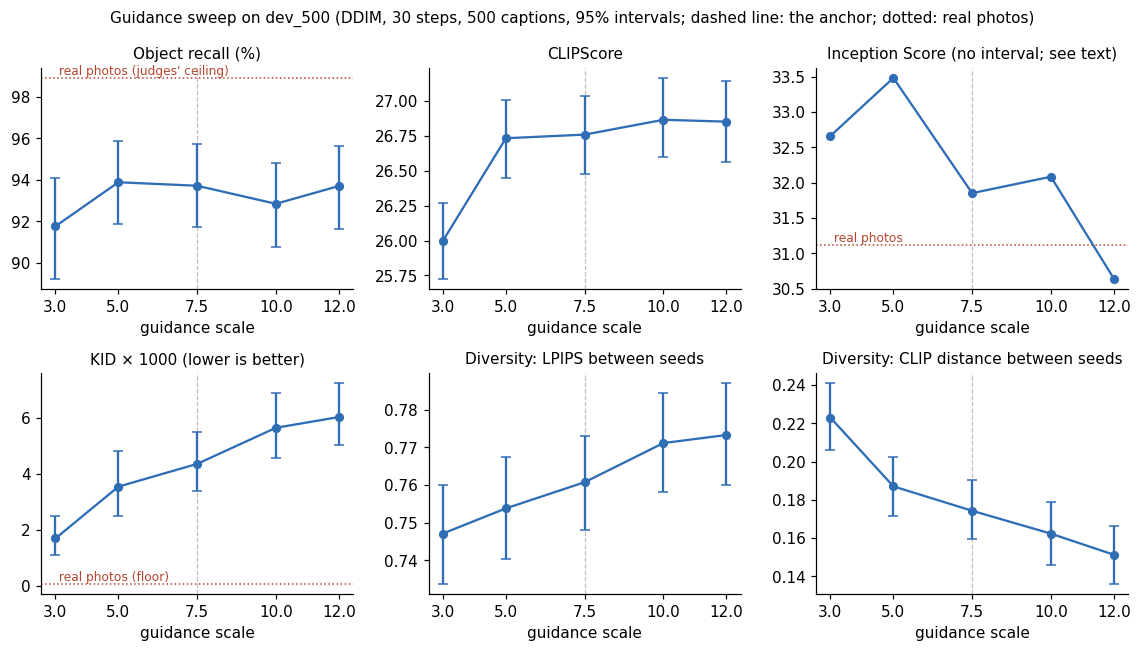

In [6]:
def errplot(ax, x, df, col, label, scale=1.0, color="#2f6db5"):
    y = df[col] * scale
    if col + "_lo" in df and df[col + "_lo"].notna().all():
        lo, hi = df[col + "_lo"] * scale, df[col + "_hi"] * scale
        ax.errorbar(x, y, yerr=[np.clip(y - lo, 0, None), np.clip(hi - y, 0, None)], fmt="o-", color=color, capsize=3, lw=1.5, ms=5)
    else:
        ax.plot(x, y, "o-", color=color, lw=1.5, ms=5)
    ax.set_title(label, fontsize=10)
    ax.set_xticks(x)
    ax.set_xlabel("guidance scale")

panels = [("recall", "Object recall (%)", 100), ("clipscore", "CLIPScore", 1), ("is", "Inception Score (no interval; see text)", 1),
          ("kid", "KID × 1000 (lower is better)", 1), ("lpips", "Diversity: LPIPS between seeds", 1),
          ("clip_distance", "Diversity: CLIP distance between seeds", 1)]
fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.0))
for ax, (col, label, scale) in zip(axes.flat, panels):
    errplot(ax, guid.guidance, guid, col, label, scale)
    ax.axvline(7.5, color="0.75", lw=0.8, ls="--", zorder=0)
for ax, val, txt in [(axes[0, 0], 100 * ceiling[0], " real photos (judges' ceiling)"), (axes[0, 2], FLOOR500["is"], " real photos"),
                     (axes[1, 0], FLOOR500["kid"], " real photos (floor)")]:
    ax.axhline(val, color="#b5452f", lw=1, ls=":")
    ax.text(guid.guidance.iloc[0], val, txt, color="#b5452f", va="bottom", fontsize=8)
fig.suptitle("Guidance sweep on dev_500 (DDIM, 30 steps, 500 captions, 95% intervals; dashed line: the anchor; dotted: real photos)", fontsize=10)
fig.tight_layout()
fig.savefig(f"{OUT}/figures/fig1_guidance_tradeoff.png", bbox_inches="tight")
plt.show()

## 6. Figure 2: what fewer or more steps cost

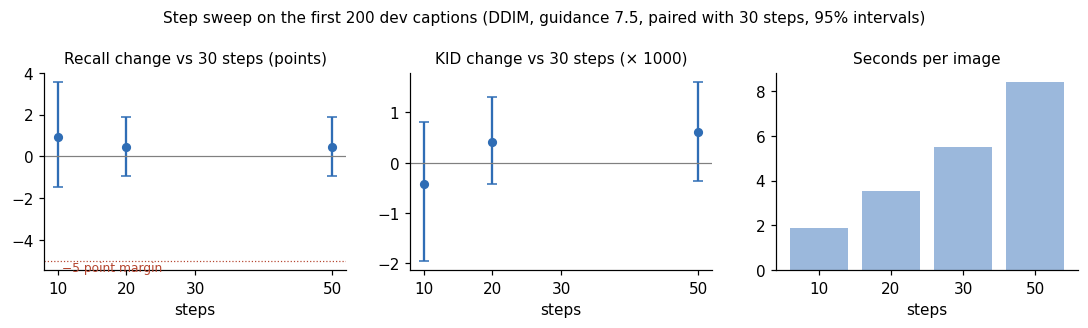

In [7]:
other = steps[steps.steps != 30]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.0))
for ax, (col, label, scale) in zip(axes[:2], [("d_recall", "Recall change vs 30 steps (points)", 100),
                                              ("d_kid", "KID change vs 30 steps (× 1000)", 1)]):
    y, lo, hi = other[col] * scale, other[col + "_lo"] * scale, other[col + "_hi"] * scale
    ax.errorbar(other.steps, y, yerr=[y - lo, hi - y], fmt="o", color="#2f6db5", capsize=3, ms=5)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xticks(STEPS); ax.set_xlabel("steps"); ax.set_title(label, fontsize=10)
axes[0].axhline(-5, color="#b5452f", lw=0.8, ls=":")
axes[0].text(STEPS[0], -5, " −5 point margin", color="#b5452f", va="top", fontsize=8)
axes[2].bar([str(n) for n in steps.steps], steps.sec_per_image, color="#9bb8dc")
axes[2].set_title("Seconds per image", fontsize=10); axes[2].set_xlabel("steps")
fig.suptitle("Step sweep on the first 200 dev captions (DDIM, guidance 7.5, paired with 30 steps, 95% intervals)", fontsize=10)
fig.tight_layout()
fig.savefig(f"{OUT}/figures/fig2_steps.png", bbox_inches="tight")
plt.show()

## 7. Figure 3: the same caption and noise across guidance

The rows are the first four dev captions (in dev order) with one labelled object whose verdict changes between guidance 3 and 12, so the grid shows where guidance makes a difference rather than a typical caption. The label under each image is the judges' verdict on the labelled object.

/tmp/ipykernel_16765/3775142935.py:17: PerformanceWarning: indexing past lexsort depth may impact performance.
  v = verdict.loc[(gcfg(g), k)]


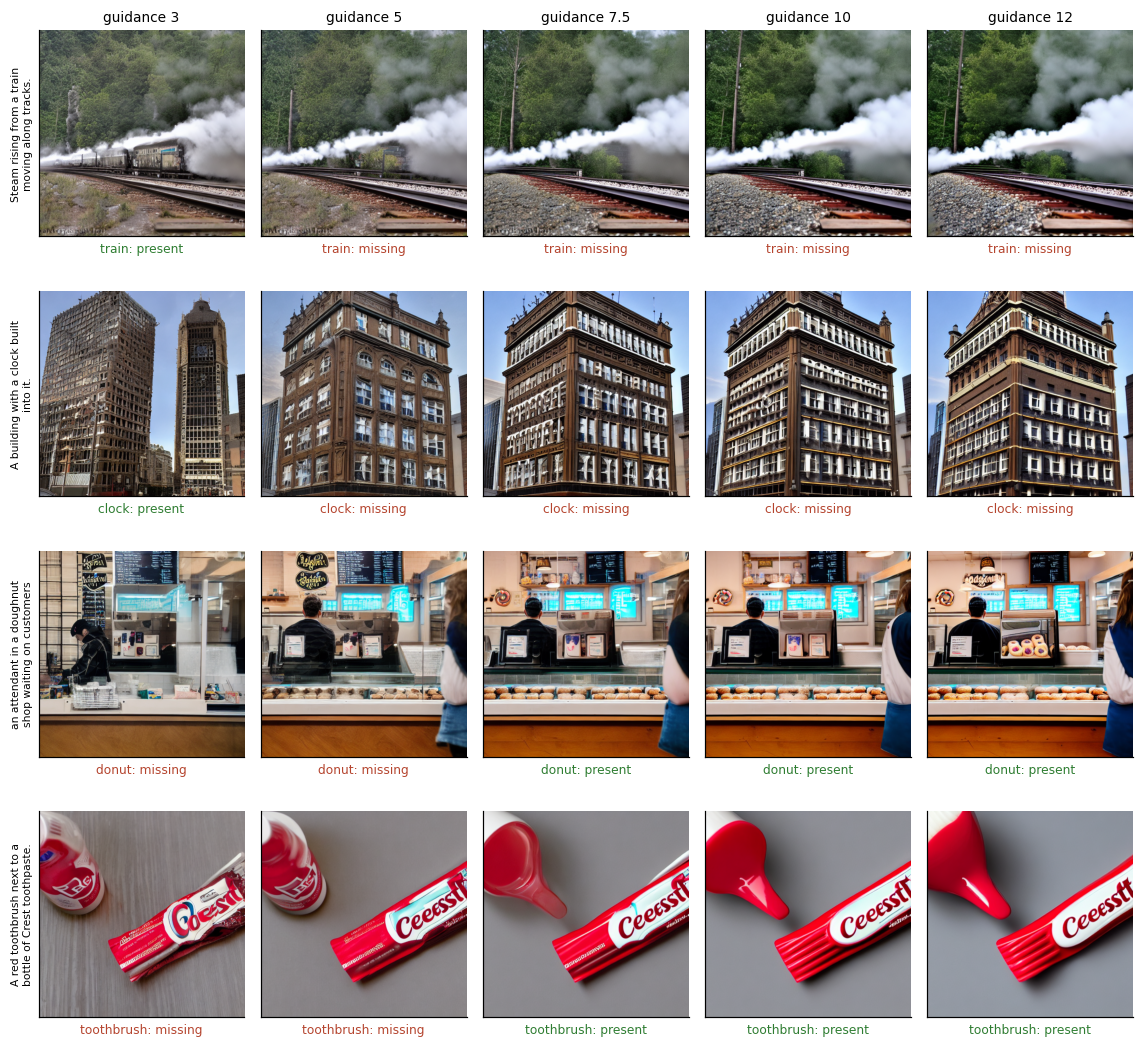

In [8]:
single = obj[(obj.config_id.isin([gcfg(3), gcfg(12)])) & (obj.seed_id == 0)]
n_obj = single.groupby(["config_id", "key"]).target_id.nunique().unstack(0).dropna()
one = n_obj[(n_obj == 1).all(axis=1)].index
p = single[single.key.isin(one)].pivot_table(index="key", columns="config_id", values="present")
changed = [k for k in dev.caption_idx.astype(str) if k in p.index and p.loc[k, gcfg(3)] != p.loc[k, gcfg(12)]][:4]
if len(changed) < 4:
    changed += [k for k in dev.caption_idx.astype(str) if k in p.index and k not in changed][:4 - len(changed)]

caption = dict(zip(dev.caption_idx.astype(str), dev.caption))
verdict = obj[obj.seed_id == 0].set_index(["config_id", "key"])
fig, axes = plt.subplots(len(changed), len(GUIDANCE), figsize=(2.1 * len(GUIDANCE), 2.45 * len(changed)), squeeze=False)
for i, k in enumerate(changed):
    for j, g in enumerate(GUIDANCE):
        ax = axes[i, j]
        ax.imshow(Image.open(f"{DRIVE}/images/{SPLIT}/{gcfg(g)}/{k}_s0.png"))
        ax.set_xticks([]); ax.set_yticks([])
        v = verdict.loc[(gcfg(g), k)]
        v = v.iloc[0] if isinstance(v, pd.DataFrame) else v
        cat = v.target_id.split(":")[1]
        ax.set_xlabel(f"{cat}: {'present' if v.present else 'missing'}", fontsize=8,
                      color="#2f7d32" if v.present else "#b5452f")
        if i == 0:
            ax.set_title(f"guidance {g:g}", fontsize=9)
    axes[i, 0].set_ylabel(textwrap.fill(textwrap.shorten(caption[k], 90), 30), fontsize=7)
fig.tight_layout()
fig.savefig(f"{OUT}/figures/fig3_guidance_examples.png", bbox_inches="tight")
plt.show()

## 8. Apply the selection rules

In [9]:
def above0(lo):  return lo > 0
def worse_kid(lo): return lo > 0          # KID interval entirely above 0 = detectably worse

cand = guid[(guid.guidance != 7.5) & guid.d_recall_lo.map(above0) & ~guid.d_kid_lo.map(worse_kid)]
best_g = float(cand.sort_values("d_recall", ascending=False).guidance.iloc[0]) if len(cand) else 7.5

s = steps.set_index("steps")
best_n = 30
if s.loc[50, "d_recall_lo"] > 0:
    best_n = 50
else:
    for n in (10, 20):
        if s.loc[n, "d_recall_lo"] > -0.05 and not worse_kid(s.loc[n, "d_kid_lo"]):
            best_n = n
            break

chosen = {"guidance": best_g, "steps": best_n, "config_id": f"ddim-leading-s{best_n}-g{best_g:g}",
          "chosen_on": "dev_500", "rules": "see the analysis notebook, section 'Selection rules'"}
json.dump(chosen, open(f"{OUT}/chosen.json", "w"), indent=2)
chosen

{'guidance': 7.5,
 'steps': 10,
 'config_id': 'ddim-leading-s10-g7.5',
 'chosen_on': 'dev_500',
 'rules': "see the analysis notebook, section 'Selection rules'"}

## 9. Section draft for the report

Writes `analysis/section_draft.md`: the method as run, the results with their numbers and intervals, and the choice. Read it against the figures before pasting it into the report; the sentences are generated from the numbers, so any wording that reads oddly for the actual pattern should be adjusted.

In [10]:
def pct(x): return f"{100 * x:.1f}%"
def pts(x): return f"{100 * x:+.1f}"
def ci_pct(lo, hi): return f"[{100 * lo:.1f}, {100 * hi:.1f}]"
def ci_pts(lo, hi): return f"[{100 * lo:+.1f}, {100 * hi:+.1f}]"
def ci(lo, hi, f="{:.2f}"): return "[" + f.format(lo) + ", " + f.format(hi) + "]"
def detect(lo, hi): return "a detectable change" if lo > 0 or hi < 0 else "no detectable change"
def moved(a, b): return "rose" if b > a else "fell"
def ruled_out(lo): return f"rules out a recall loss of more than {max(0, -100 * lo):.1f} points" if lo < 0 else "shows no recall loss"

G = guid.set_index("guidance"); S = steps.set_index("steps")
lo_g, hi_g = G.loc[3], G.loc[12]
dev_ims = ims[ims.split == SPLIT]
n_dev, n_flag = len(dev_ims), int(dev_ims.flagged.sum())
run_logs = [f"{DRIVE}/runs.csv"] + ([f"{DRIVE}/steps_from_santhosh/runs.csv"] if os.path.exists(f"{DRIVE}/steps_from_santhosh/runs.csv") else [])
gpus = pd.concat([pd.read_csv(f) for f in run_logs]).query("split == 'dev_500'").drop_duplicates("config_id", keep="last").set_index("config_id").gpu
step_gpus = sorted({str(gpus.get(scfg(n), "unknown")) for n in STEPS})
timing_note = (f"on a {step_gpus[0]}" if len(step_gpus) == 1 else
               f"(timings come from different GPUs, {', '.join(step_gpus)}, so they compare only within one GPU)")

lines = ["### Guidance scale and number of sampling steps\n"]
lines.append(
    "**Setup.** All images were generated with the group's shared protocol (`m2-v1`, diffusers 0.42.1): Stable Diffusion 1.5 "
    "in half precision with its CLIP text encoder, DDIM (eta 0), leading timestep spacing and the safety checker on. "
    "Each sweep changed one setting away from the anchor (30 steps, guidance 7.5). The starting noise for a caption was "
    "drawn on the CPU from seed = 100000 × seed_id + caption_idx, so every setting painted each caption from identical noise "
    "and settings can be compared caption by caption. The guidance sweep (3, 5, 7.5, 10, 12) used all 500 captions of "
    "`dev_500` with one seed; the step sweep (10, 20, 30, 50) used its first 200. The first 100 captions were painted a second "
    "time (seed_id 1) at every guidance value to measure diversity. The final comparison on the test captions used three seeds "
    f"per caption. {n_flag} of the {n_dev:,} dev images ({100 * n_flag / n_dev:.1f}%) were blacked out by the safety checker and left out.\n")
lines.append(
    "**Measures.** Object recall is the share of the labelled objects in the captions (559 in `dev_500`) that appear in the "
    "image, judged by Faster R-CNN v2 (class score ≥ 0.5) and OWL-ViT (\"a photo of a {class}\", score ≥ 0.1); an object counts as "
    f"present if either judge finds it. On the real photos behind the same captions the judges find {pct(ceiling[0])} "
    f"{ci_pct(ceiling[1], ceiling[2])} of the objects, the ceiling for this measure. Image quality is measured by KID "
    "(× 1000), FID and the Inception Score against 2,000 COCO photos that share no photo with any caption set, and text alignment "
    "by CLIPScore (ViT-L/14). FID and the Inception Score depend on the number of images, so each is reported next to the "
    f"real-photo floor, the score of the real photos behind the same captions at the same size: with 500 images real photos "
    f"get FID {FLOOR500['fid']:.1f}, KID {FLOOR500['kid']:.2f} {ci(FLOOR500['kid_lo'], FLOOR500['kid_hi'])} and IS {FLOOR500['is']:.2f}; "
    f"with 200, FID {FLOOR200['fid']:.1f}, KID {FLOOR200['kid']:.2f} and IS {FLOOR200['is']:.2f}. The Inception Score rates how "
    "confidently an ImageNet classifier labels each image and how varied the labels are; it was designed for single-object "
    "ImageNet-like images and says less about COCO scenes, so it is reported for completeness; higher is not better here "
    "when it exceeds the real photos' score. Intervals are 95% bootstrap intervals over captions; differences between settings are "
    "paired on the same captions and noise. FID and the Inception Score of a single set carry no interval: for the Inception "
    "Score, a resample repeats images, which the score reads as lost variety, so only paired differences, where that shift "
    "falls on both sides, get one.\n")
para = (
    f"**Guidance.** Raising guidance from 3 to 12 moved object recall from {pct(lo_g.recall)} to {pct(hi_g.recall)}; "
    f"against the anchor (7.5, {pct(G.loc[7.5].recall)}) the paired differences were {pts(lo_g.d_recall)} points "
    f"{ci_pts(lo_g.d_recall_lo, lo_g.d_recall_hi)} at 3 and {pts(hi_g.d_recall)} {ci_pts(hi_g.d_recall_lo, hi_g.d_recall_hi)} at 12 "
    f"({detect(lo_g.d_recall_lo, lo_g.d_recall_hi)} at 3, {detect(hi_g.d_recall_lo, hi_g.d_recall_hi)} at 12). "
    f"CLIPScore went from {lo_g.clipscore:.2f} to {hi_g.clipscore:.2f} (paired change at 3: {lo_g.d_clipscore:+.2f} "
    f"{ci(lo_g.d_clipscore_lo, lo_g.d_clipscore_hi, '{:+.2f}')}; at 12: {hi_g.d_clipscore:+.2f} "
    f"{ci(hi_g.d_clipscore_lo, hi_g.d_clipscore_hi, '{:+.2f}')}). KID {moved(lo_g.kid, hi_g.kid)} from {lo_g.kid:.2f} to {hi_g.kid:.2f} "
    f"(paired change at 3: {lo_g.d_kid:+.2f} {ci(lo_g.d_kid_lo, lo_g.d_kid_hi, '{:+.2f}')}; at 12: {hi_g.d_kid:+.2f} "
    f"{ci(hi_g.d_kid_lo, hi_g.d_kid_hi, '{:+.2f}')}), against a real-photo floor of {FLOOR500['kid']:.2f}; FID went from "
    f"{lo_g.fid:.1f} to {hi_g.fid:.1f} (floor {FLOOR500['fid']:.1f}). The Inception Score {moved(lo_g['is'], hi_g['is'])} from "
    f"{lo_g['is']:.2f} to {hi_g['is']:.2f} (paired change at 12: {hi_g.d_is:+.2f} {ci(hi_g.d_is_lo, hi_g.d_is_hi, '{:+.2f}')}; "
    f"real photos {FLOOR500['is']:.2f}).")
if "lpips" in guid:
    para += (f" For diversity, the LPIPS between a caption's two seeds {moved(lo_g.lpips, hi_g.lpips)} from {lo_g.lpips:.3f} "
             f"{ci(lo_g.lpips_lo, lo_g.lpips_hi, '{:.3f}')} at guidance 3 to {hi_g.lpips:.3f} {ci(hi_g.lpips_lo, hi_g.lpips_hi, '{:.3f}')} "
             f"at 12, while their CLIP image distance {moved(lo_g.clip_distance, hi_g.clip_distance)} from {lo_g.clip_distance:.3f} "
             f"{ci(lo_g.clip_distance_lo, lo_g.clip_distance_hi, '{:.3f}')} to {hi_g.clip_distance:.3f} "
             f"{ci(hi_g.clip_distance_lo, hi_g.clip_distance_hi, '{:.3f}')}.")
    if (hi_g.lpips > lo_g.lpips) != (hi_g.clip_distance > lo_g.clip_distance):
        para += (" The two measures disagree: LPIPS responds to texture and fine detail, CLIP distance to content, so higher "
                 f"guidance made the two pictures {'more' if hi_g.clip_distance < lo_g.clip_distance else 'less'} alike in what "
                 f"they show while {'more' if hi_g.lpips > lo_g.lpips else 'less'} different in detail.")
para += " Figure 1 shows all six measures; Figure 3 shows captions whose object is judged differently at 3 and at 12.\n"
lines.append(para)
s10, s20, s50 = S.loc[10], S.loc[20], S.loc[50]
lines.append(
    f"**Steps.** Against 30 steps on the same 200 captions, recall changed by {pts(s10.d_recall)} points "
    f"{ci_pts(s10.d_recall_lo, s10.d_recall_hi)} at 10 steps, {pts(s20.d_recall)} {ci_pts(s20.d_recall_lo, s20.d_recall_hi)} at 20 "
    f"and {pts(s50.d_recall)} {ci_pts(s50.d_recall_lo, s50.d_recall_hi)} at 50; KID changed by {s10.d_kid:+.2f} "
    f"{ci(s10.d_kid_lo, s10.d_kid_hi, '{:+.2f}')}, {s20.d_kid:+.2f} {ci(s20.d_kid_lo, s20.d_kid_hi, '{:+.2f}')} and "
    f"{s50.d_kid:+.2f} {ci(s50.d_kid_lo, s50.d_kid_hi, '{:+.2f}')} (real-photo floor at 200 images: {FLOOR200['kid']:.2f}), and the "
    f"Inception Score by {s10.d_is:+.2f}, {s20.d_is:+.2f} and {s50.d_is:+.2f}. Because both sides of each comparison start from the "
    f"same noise, the comparison is paired: the 10-step interval {ruled_out(s10.d_recall_lo)}, the 20-step interval "
    f"{ruled_out(s20.d_recall_lo)}. One image took {s10.sec_per_image:.1f} s at 10 steps, {S.loc[30].sec_per_image:.1f} s at 30 and "
    f"{s50.sec_per_image:.1f} s at 50 {timing_note} (Figure 2).\n")
lines.append(
    f"**Choice.** By rules fixed before the results were seen (raise recall without a detectable KID cost; otherwise keep the anchor; "
    f"fewest steps that lose less than 5 points of recall), the setting carried to the test captions is "
    f"**guidance {best_g:g}, {best_n} steps** (`{chosen['config_id']}`). It is evaluated on `eval_500`, which no choice has used.\n")

md = ["| Guidance | Object recall | CLIPScore | KID × 1000 | FID | IS |", "|---|---|---|---|---|---|"]
for _, r in guid.iterrows():
    md.append(f"| {r.guidance:g} | {pct(r.recall)} {ci_pct(r.recall_lo, r.recall_hi)} | {r.clipscore:.2f} | "
              f"{r.kid:.2f} {ci(r.kid_lo, r.kid_hi)} | {r.fid:.1f} | {r['is']:.2f} |")
md.append(f"| Real photos (floor) | {pct(ceiling[0])} (judges' ceiling) | – | {FLOOR500['kid']:.2f} {ci(FLOOR500['kid_lo'], FLOOR500['kid_hi'])} | "
          f"{FLOOR500['fid']:.1f} | {FLOOR500['is']:.2f} |")
lines.append("**Table.** Guidance sweep on `dev_500` (500 captions, DDIM, 30 steps, one seed; 95% intervals). The last row is the "
             "real photos behind the same 500 captions.\n\n" + "\n".join(md) + "\n")

draft = "\n".join(lines)
open(f"{OUT}/section_draft.md", "w").write(draft)
print(draft)

### Guidance scale and number of sampling steps

**Setup.** All images were generated with the group's shared protocol (`m2-v1`, diffusers 0.42.1): Stable Diffusion 1.5 in half precision with its CLIP text encoder, DDIM (eta 0), leading timestep spacing and the safety checker on. Each sweep changed one setting away from the anchor (30 steps, guidance 7.5). The starting noise for a caption was drawn on the CPU from seed = 100000 × seed_id + caption_idx, so every setting painted each caption from identical noise and settings can be compared caption by caption. The guidance sweep (3, 5, 7.5, 10, 12) used all 500 captions of `dev_500` with one seed; the step sweep (10, 20, 30, 50) used its first 200. The first 100 captions were painted a second time (seed_id 1) at every guidance value to measure diversity. The final comparison on the test captions used three seeds per caption. 20 of the 3,600 dev images (0.6%) were blacked out by the safety checker and left out.

**Measures.** Object recal

## 10. Final numbers on eval_500: the chosen setting against the anchor, three seeds

The 500 test captions painted with seed_ids 0, 1 and 2 under both settings. Each seed is shown on its own, next to the real-photo floor for 500 images; the pooled comparison uses all three seeds, resampling a caption together with its seeds. This is the only time `eval_500` is read.

In [11]:
eobj, eims = sc.load_objects(SCORES, "eval_500"), sc.load_images(SCORES, "eval_500")
if len(eims):
    final_cfg = chosen["config_id"]
    cfgs = [ANCHOR] + ([final_cfg] if final_cfg != ANCHOR else [])
    SEEDS = tuple(sorted(set.intersection(*[set(eims[eims.config_id == c].seed_id) for c in cfgs])))
    rows = []
    for c in cfgs:
        for sd in SEEDS:
            r = sc.recall(eobj, c, "eval_500", seed_ids=(sd,))
            k, _, f = sc.load_features(SCORES, "eval_500", c, seed_ids=(sd,))
            lg = sc.load_logits(SCORES, "eval_500", c, seed_ids=(sd,))[2]
            rows.append({"config_id": c, "seed_id": sd, "images": len(f), "objects": r[3], "recall": r[0],
                         "clipscore": eims[(eims.config_id == c) & (eims.seed_id == sd) & (eims.flagged == 0)].clipscore.mean(),
                         "kid": sc.kid_with_ci(f, f_ref)[0], "fid": sc.fid(f, f_ref), "is": sc.InceptionScore(lg).value()})
    per_seed = pd.DataFrame(rows)
    per_seed.to_csv(f"{OUT}/final_eval_500_per_seed.csv", index=False)
    display(per_seed.round(3))

    pooled = []
    for c in cfgs:
        r = sc.recall(eobj, c, "eval_500", seed_ids=SEEDS)
        k, sds, f = sc.load_features(SCORES, "eval_500", c, seed_ids=SEEDS)
        kv = sc.kid_with_ci(f, f_ref, groups=k)
        ps = per_seed[per_seed.config_id == c]
        pooled.append({"config_id": c, "seeds": len(SEEDS), "images": len(f), "objects": r[3], "recall": r[0], "recall_lo": r[1],
                       "recall_hi": r[2], "kid": kv[0], "kid_lo": kv[1], "kid_hi": kv[2],
                       "fid_mean_per_seed": ps.fid.mean(), "is_mean_per_seed": ps["is"].mean(), "clipscore": ps.clipscore.mean()})
    pooled = pd.DataFrame(pooled)
    pooled.to_csv(f"{OUT}/final_eval_500.csv", index=False)
    display(pooled.round(3))
    print(f"real-photo floor, eval_500 (500 photos): FID {FLOOR_EVAL['fid']:.1f}, KID {FLOOR_EVAL['kid']:.2f}, IS {FLOOR_EVAL['is']:.2f}")

    P = pooled.set_index("config_id")
    a = P.loc[ANCHOR]
    text = (f"\n**Test captions (`eval_500`, {len(SEEDS)} seed{'s' if len(SEEDS) > 1 else ''} per caption).** The anchor found "
            f"{pct(a.recall)} {ci_pct(a.recall_lo, a.recall_hi)} of {int(a.objects)} labelled-object instances, with KID {a.kid:.2f} "
            f"{ci(a.kid_lo, a.kid_hi)}, FID {a.fid_mean_per_seed:.1f} and IS {a.is_mean_per_seed:.2f} (averages of the per-seed values, "
            f"500 images each) and CLIPScore {a.clipscore:.2f}; the real photos behind these captions get FID {FLOOR_EVAL['fid']:.1f}, "
            f"KID {FLOOR_EVAL['kid']:.2f} and IS {FLOOR_EVAL['is']:.2f}.")
    if final_cfg != ANCHOR:
        b = P.loc[final_cfg]
        d = sc.paired_recall_diff(eobj, final_cfg, ANCHOR, "eval_500", seed_ids=SEEDS)
        kd = sc.paired_kid_diff(SCORES, "eval_500", final_cfg, ANCHOR, f_ref, seed_ids=SEEDS)
        isd = sc.paired_is_diff(SCORES, "eval_500", final_cfg, ANCHOR, seed_ids=SEEDS)
        cd = sc.paired_mean_diff(eims[eims.flagged == 0], final_cfg, ANCHOR, "clipscore", seed_ids=SEEDS)
        same_sign = (per_seed.pivot(index="seed_id", columns="config_id", values="recall").pipe(lambda t: t[final_cfg] - t[ANCHOR]))
        text += (f" The chosen setting found {pct(b.recall)}: a paired change of {pts(d[0])} points {ci_pts(d[1], d[2])} "
                 f"({detect(d[1], d[2])}), with KID {kd[0]:+.2f} {ci(kd[1], kd[2], '{:+.2f}')} ({detect(kd[1], kd[2])}), "
                 f"IS {isd[0]:+.2f} {ci(isd[1], isd[2], '{:+.2f}')} ({detect(isd[1], isd[2])}) and CLIPScore {cd[0]:+.2f} "
                 f"{ci(cd[1], cd[2], '{:+.2f}')} ({detect(cd[1], cd[2])}), "
                 f"at {eims[eims.config_id == final_cfg].seconds.mean():.1f} s per image instead of "
                 f"{eims[eims.config_id == ANCHOR].seconds.mean():.1f} s. Per seed, the recall change was "
                 + ", ".join(f"{pts(v)}" for v in same_sign.values) + " points.")
        fl = FLOOR_EVAL["is"]
        closer = "closer to" if abs(b.is_mean_per_seed - fl) < abs(a.is_mean_per_seed - fl) else "further from"
        text += (f" On the Inception Score the anchor ({a.is_mean_per_seed:.2f}) sits {'above' if a.is_mean_per_seed > fl else 'below'} "
                 f"the real photos ({fl:.2f}) and the chosen setting ({b.is_mean_per_seed:.2f}) {closer} them, so its lower score "
                 + ("does not mean worse images" + (": with KID, it suggests the chosen setting's images are, if anything, closer to real photos"
                     if kd[2] < 0 else "") if closer == "closer to" else "should be weighed against its KID") + ".")
    else:
        text += " The rules kept the anchor, so these are also the numbers for the chosen setting."
    open(f"{OUT}/section_draft.md", "a").write(text + "\n")
    print(text)
else:
    print("eval_500 not scored yet")

,config_id,seed_id,images,objects,recall,clipscore,kid,fid,is
0,ddim-leading-s30-g7.5,0,499,567,0.949,26.597,4.986,84.788,35.961
1,ddim-leading-s30-g7.5,1,500,568,0.938,26.732,4.150,84.633,35.077
2,ddim-leading-s30-g7.5,2,500,568,0.944,26.757,4.178,85.262,36.159
3,ddim-leading-s10-g7.5,0,498,566,0.940,26.650,3.210,84.998,32.301
4,ddim-leading-s10-g7.5,1,498,567,0.942,26.813,3.713,85.170,31.369
5,ddim-leading-s10-g7.5,2,498,565,0.949,26.635,3.856,85.046,33.994


,config_id,seeds,images,objects,recall,recall_lo,recall_hi,kid,kid_lo,kid_hi,fid_mean_per_seed,is_mean_per_seed,clipscore
0,ddim-leading-s30-g7.5,3,1499,1703,0.944,0.93,0.956,4.655,4.009,5.917,84.895,35.732,26.695
1,ddim-leading-s10-g7.5,3,1494,1698,0.943,0.93,0.956,3.819,3.483,4.728,85.071,32.555,26.699


real-photo floor, eval_500 (500 photos): FID 75.1, KID -0.16, IS 33.58

**Test captions (`eval_500`, 3 seeds per caption).** The anchor found 94.4% [93.0, 95.6] of 1703 labelled-object instances, with KID 4.66 [4.01, 5.92], FID 84.9 and IS 35.73 (averages of the per-seed values, 500 images each) and CLIPScore 26.70; the real photos behind these captions get FID 75.1, KID -0.16 and IS 33.58. The chosen setting found 94.3%: a paired change of +0.0 points [-1.0, +1.0] (no detectable change), with KID -0.85 [-1.44, -0.32] (a detectable change), IS -3.30 [-5.54, -1.90] (a detectable change) and CLIPScore +0.02 [-0.10, +0.14] (no detectable change), at 1.7 s per image instead of 4.7 s. Per seed, the recall change was -0.9, +0.3, +0.5 points. On the Inception Score the anchor (35.73) sits above the real photos (33.58) and the chosen setting (32.55) closer to them, so its lower score does not mean worse images: with KID, it suggests the chosen setting's images are, if anything, closer to real 

## 10b. Figure 4: early samples (anchor, eval_500)

Eight anchor images (DDIM, 30 steps, guidance 7.5, seed_id 0) from the test captions, each with its caption and the judges' verdict on every labelled object. To avoid hand-picking, they are chosen by a fixed rule in `eval_500` order: the first five captions in which every labelled object is found, and the first three in which exactly one is missing, preferring captions with at least two labelled objects in both groups. Under each image, ✓ means at least one judge found the object, ✗ means both missed it; the numbers are the Faster R-CNN and OWL-ViT scores (thresholds 0.5 and 0.1).

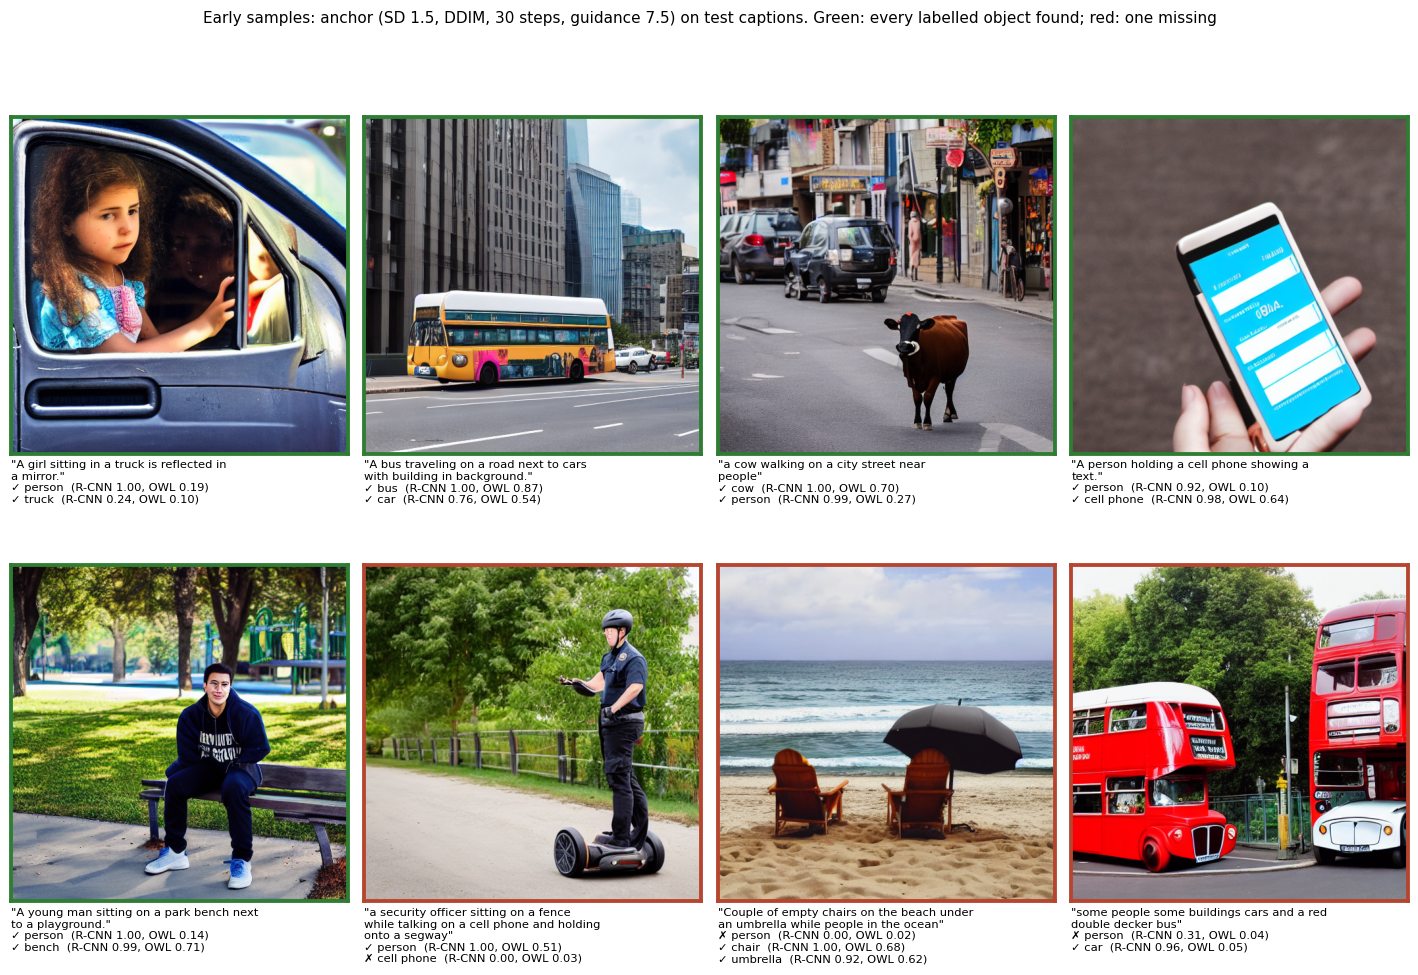

In [12]:
eobj0 = sc.load_objects(SCORES, "eval_500")
eobj0 = eobj0[(eobj0.config_id == ANCHOR) & (eobj0.seed_id == 0)].copy()
eobj0["category"] = eobj0.target_id.str.split(":").str[1]
ev = sc.load_split("eval_500")
order = ev.caption_idx.astype(str).tolist()
caption_e = dict(zip(order, ev.caption))
per = eobj0.groupby("key").agg(n=("present", "size"), found=("present", "sum"))
per["missing"] = per.n - per.found

def first(cond, k):
    keys = [x for x in order if x in per.index and cond(per.loc[x])]
    multi = [x for x in keys if per.loc[x, "n"] >= 2]
    return (multi + [x for x in keys if x not in multi])[:k]

complete = first(lambda r: r.missing == 0, 5)
one_missing = first(lambda r: r.missing == 1, 3)
picked = [(k, True) for k in complete] + [(k, False) for k in one_missing]
pd.DataFrame([{"caption_idx": k, "caption": caption_e[k], "group": "all objects found" if ok else "one object missing",
               "objects": per.loc[k, "n"], "missing": per.loc[k, "missing"]} for k, ok in picked]).to_csv(f"{OUT}/fig4_early_samples.csv", index=False)

fig, axes = plt.subplots(2, 4, figsize=(13, 9.2), squeeze=False)
for ax, (k, ok) in zip(axes.flat, picked):
    ax.imshow(Image.open(f"{DRIVE}/images/eval_500/{ANCHOR}/{k}_s0.png"))
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_edgecolor("#2f7d32" if ok else "#b5452f"); side.set_linewidth(2.5); side.set_visible(True)
    v = eobj0[eobj0.key == k]
    verdicts = [f"{'✓' if r.present else '✗'} {r.category}  (R-CNN {r.frcnn_score:.2f}, OWL {r.owl_score:.2f})" for r in v.itertuples()]
    ax.set_xlabel(textwrap.fill(f'"{caption_e[k]}"', 42) + "\n" + "\n".join(verdicts), fontsize=7.5, loc="left")
for ax in axes.flat[len(picked):]:
    ax.axis("off")
fig.suptitle("Early samples: anchor (SD 1.5, DDIM, 30 steps, guidance 7.5) on test captions. Green: every labelled object found; "
             "red: one missing", fontsize=10)
fig.tight_layout()
fig.savefig(f"{OUT}/figures/fig4_early_samples.png", bbox_inches="tight")
plt.show()

## 11. Files for the group repository

Copies the generation log and every result table into `MyDrive/m2/export/`, ready to upload to `milestone-2/expN/` (the images stay on Drive; the three figures are small enough for GitHub).

In [13]:
EXPORT = f"{DRIVE}/export"
os.makedirs(f"{EXPORT}/figures", exist_ok=True)
for f in ["runs.csv", "images.csv"]:
    shutil.copy(f"{DRIVE}/{f}", EXPORT)
for f in os.listdir(OUT):
    if f.endswith((".csv", ".json", ".md")):
        shutil.copy(f"{OUT}/{f}", EXPORT)
for f in os.listdir(f"{OUT}/figures"):
    shutil.copy(f"{OUT}/figures/{f}", f"{EXPORT}/figures")
for sp in ["dev_500", "eval_500"]:      # rebuilt with the current scoring code rather than copied
    name = "summary_dev_500_all_captions.csv" if sp == "dev_500" else "summary_eval_500.csv"
    sc.summary_table(SCORES, split=sp).to_csv(f"{EXPORT}/{name}", index=False)
sorted(os.listdir(EXPORT))

['chosen.json',
 'fig4_early_samples.csv',
 'figures',
 'final_eval_500.csv',
 'final_eval_500_per_seed.csv',
 'guidance_dev_500.csv',
 'images.csv',
 'real_photo_floor.csv',
 'runs.csv',
 'section_draft.md',
 'steps_dev_500_first200.csv',
 'summary_dev_500_all_captions.csv',
 'summary_eval_500.csv']